# 2. Ridge in p >> n: the kernel trick and the SVD

**Learning goals**: compute ridge cheaply when p is huge, see what it does to the data's principal
directions, and connect it to principal components regression (PCR).

$$\hat\beta = (X^\top X + \lambda I_p)^{-1} X^\top y = X^\top (X X^\top + \lambda I_n)^{-1} y$$

The second form (the **kernel** or dual form) inverts an $n \times n$ matrix instead of a $p \times p$ one.
With 900 lines and 18,000 genes that is the difference between a 900² and an 18,000² problem.
Through the SVD $X = UDV^\top$ (only $n$ non-zero singular values), every $\lambda$ comes almost
free once $U$, $D$, $V$ are known:
$$\hat\beta(\lambda) = V \,\mathrm{diag}\Big(\frac{d_j}{d_j^2+\lambda}\Big) U^\top y$$
This is exactly how the project's `RidgeModel` tunes $\lambda$ (`drugresponse.models._ridge_path`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(7)

In [2]:
import time
n, p = 400, 8000
X = rng.normal(size=(n, p)); y = X[:, :20] @ rng.normal(size=20) + rng.normal(size=n)
lam = 50.0
t = time.time(); b_primal = np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y); t_primal = time.time() - t
t = time.time(); b_dual = X.T @ np.linalg.solve(X @ X.T + lam * np.eye(n), y); t_dual = time.time() - t
print(f"primal (p x p): {t_primal:.2f}s   dual (n x n): {t_dual:.3f}s   max difference {np.abs(b_primal - b_dual).max():.1e}")

primal (p x p): 6.09s   dual (n x n): 0.030s   max difference 6.1e-15


## Shrinkage along principal directions

In [3]:
# The project's data: one drug, its screened cell lines, 2,000 most variable genes
from drugresponse.experiment import Store
from drugresponse.models import Design
S = Store()
drug_name = "Nutlin-3a (-)"
d = S.drugs.index[S.drugs.drug_name == drug_name][0]
ok = S.R[d].notna().values
des = Design(2000).fit(S.Ev[ok], S.tissue[ok], S.sanger[ok])
X = des.transform(S.Ev[ok], S.tissue[ok], S.sanger[ok])[:, ~des.is_tissue()]   # genes only
y = S.R[d].values[ok]
genes = S.genes[des.genes_]
print(f"{drug_name}: {X.shape[0]} cell lines x {X.shape[1]} genes")

Nutlin-3a (-): 943 cell lines x 2000 genes


effective degrees of freedom: [903.6 330.1  12.7] out of 943


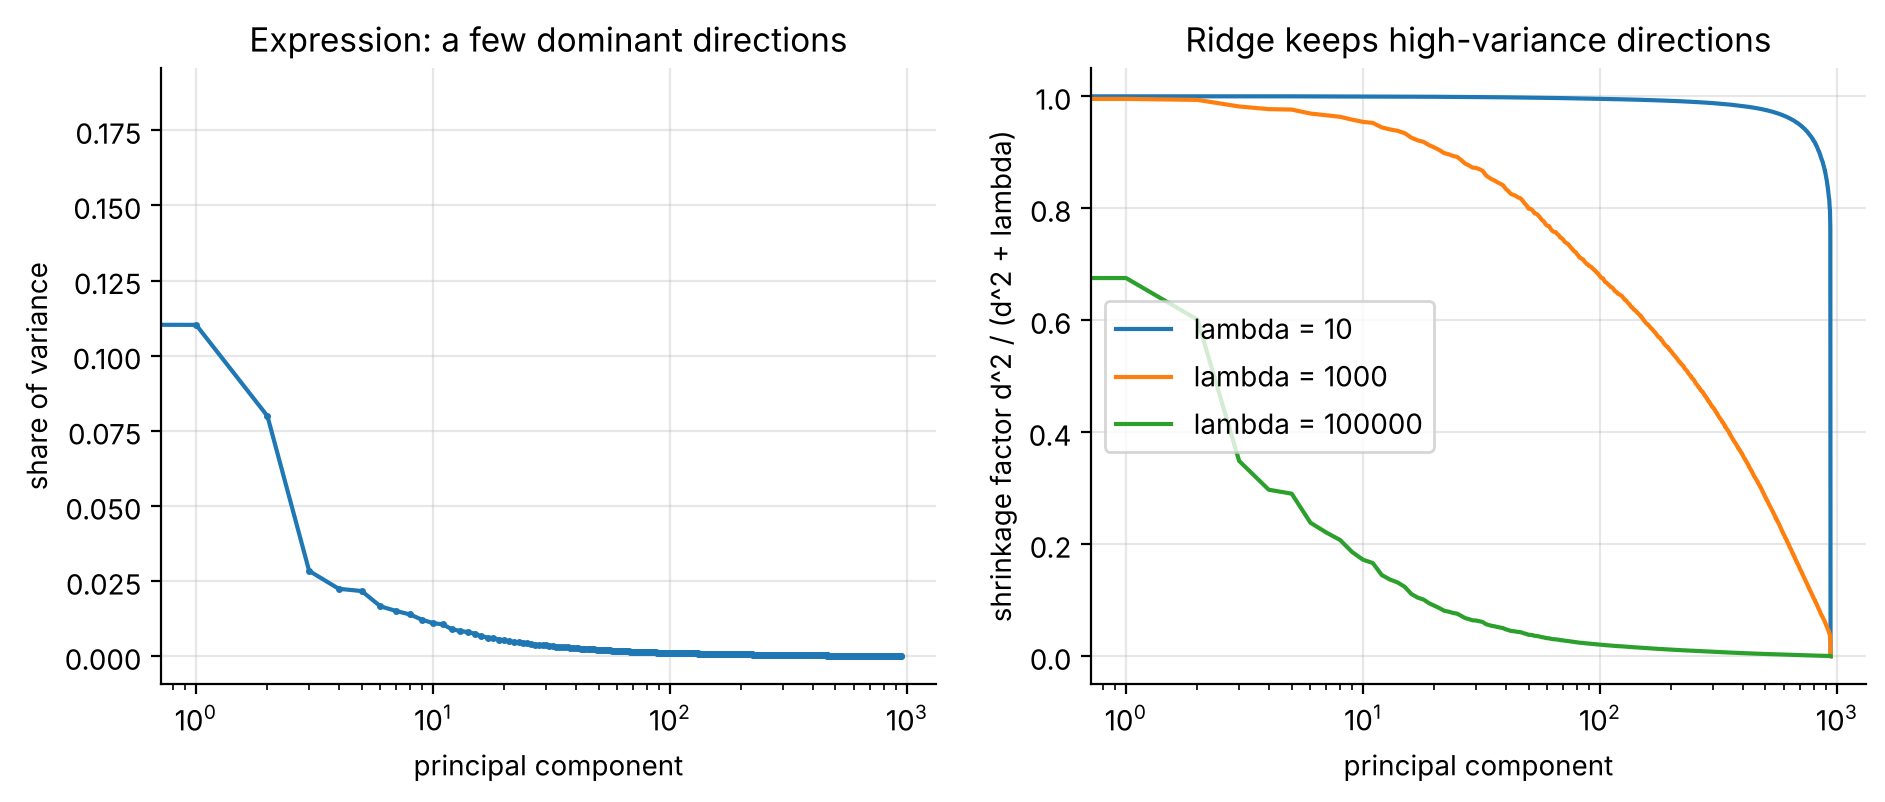

In [4]:
Xc = X - X.mean(0); yc = y - y.mean()
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(s ** 2 / np.sum(s ** 2), ".-", ms=3); ax[0].set_xscale("log")
ax[0].set(xlabel="principal component", ylabel="share of variance", title="Expression: a few dominant directions")
for lam in [1e1, 1e3, 1e5]:
    ax[1].plot(s ** 2 / (s ** 2 + lam), label=f"lambda = {lam:g}")
ax[1].set_xscale("log"); ax[1].legend()
ax[1].set(xlabel="principal component", ylabel="shrinkage factor d^2 / (d^2 + lambda)",
          title="Ridge keeps high-variance directions")
df = [np.sum(s ** 2 / (s ** 2 + lam)) for lam in [1e1, 1e3, 1e5]]
print("effective degrees of freedom:", np.round(df, 1), "out of", len(s))

Gene expression is dominated by a few large axes of variation (tissue of origin, proliferation,
epithelial vs mesenchymal state). Ridge keeps those and shrinks the hundreds of small directions,
which are mostly noise with n = 900. PCR does the same with a hard cut: keep the first k
components, drop the rest. In this project PCR is the "dense benchmark".

**Key takeaways**
* Use the n x n (kernel) form when p >> n; tune all lambdas from one SVD.
* Effective degrees of freedom, not the number of genes, measure ridge's complexity.
* Ridge assumes many small effects spread across correlated genes, a natural prior for expression.